# Fair value of central-Madrid flats — training pipeline

**The business question.** A buy-to-let investor receives hundreds of new for-sale listings in Madrid's central
districts every quarter and can only visit a few. The model estimates what each flat *should* ask per m², given its
characteristics and location, like valuing a company with a multiple adjusted for its features. Listings that ask
clearly less than that "fair value" are flagged as candidate bargains to visit.

**The model.** One linear regression on `log(€/m²)`, trained three ways on the same data split:
1. scikit-learn,
2. PyTorch "by hand" (raw tensors, autograd, update written manually),
3. the standard PyTorch workflow (`nn.Module` + `torch.optim` + `DataLoader`).

**How to run:** `uv run python main.py train`. Everything the dashboard needs is saved in `artifacts/`; the dashboard
never retrains.

| § | Section | § | Section |
|---|---|---|---|
| 1 | Data | 7 | Final input matrices |
| 2 | Business framing → pipeline decisions | 8–10 | The three implementations |
| 3 | Cleaning | 11 | Comparison on the test quarter |
| 4 | Target and time split | 12 | Business layer: the bargain screen |
| 5 | Feature engineering | 13 | Saving the artifacts |
| 6 | Model selection on the validation quarter | | |

The reusable code (cleaning, features, metrics, the `nn.Module`) lives in `pipeline.py`, so that the dashboard turns
listings into model inputs with exactly the same code as training.

In [1]:
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import torch
from IPython import get_ipython
from IPython.display import display as _display
from sklearn.linear_model import LinearRegression, Ridge
from torch.utils.data import DataLoader, TensorDataset

import matplotlib

IN_NOTEBOOK = get_ipython() is not None
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # main.py runs this notebook as a plain script: never open plot windows
import matplotlib.pyplot as plt

import pipeline as P

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42                      # fixed seed: shuffling and initialisation are reproducible
np.random.seed(SEED)
torch.manual_seed(SEED)

ART = P.ARTIFACTS_DIR
FIG = ART / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
COLORS = {"sklearn": "#2a78d6", "manual": "#eb6834", "module": "#1baf7a", "baseline": "#898781"}


def show(obj):
    # display() inside Jupyter, print() when main.py runs the notebook as a script
    if IN_NOTEBOOK:
        _display(obj)
    else:
        print(obj.to_string() if isinstance(obj, pd.DataFrame) else obj)


def save_fig(fig, name):
    # every figure is also saved to artifacts/figures so REPORT.md can use it
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    if IN_NOTEBOOK:
        _display(fig)
    plt.close(fig)

## 1. Data

**Source:** the open [`idealista18`](https://github.com/paezha/idealista18) dataset (Rey-Blanco, Arbués & López, 2024).
It contains every for-sale listing published on idealista.com in Madrid during 2018, one snapshot per quarter, enriched
with cadastre data (construction year, building height, cadastral quality). `data/prepare_dataset.py` converts the
original R files into the committed `data/madrid_sale_2018.csv.gz` and `data/madrid_barrios.geojson` (neighbourhood
polygons).

**One row = one listing ad in one quarter.** 94,815 rows × 41 columns for the whole city.

Three things the publisher did to protect privacy matter later:
- prices got random noise of ±2.5% and were rounded to €1,000, so **no model can be perfect**;
- coordinates were moved 30–60 m, but **always inside the same neighbourhood**;
- ads above €10,444/m², below €5k or above €4M were removed, so **the luxury top is cut off**.

In [2]:
raw = P.load_listings()
polygons = P.load_neighbourhoods()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns, {raw['ASSETID'].nunique():,} distinct flats")
show(raw.head(3).T.head(20))
show(raw["PERIOD"].map(P.QUARTER_LABEL).value_counts().sort_index().rename("ads per quarter").to_frame())

94,815 rows x 41 columns, 75,804 distinct flats


,0,1,2
ASSETID,A15019136831406238029,A6677225905472065344,A13341979748618524775
PERIOD,201803,201803,201803
PRICE,"126,000.0000","235,000.0000","373,000.0000"
UNITPRICE,"2,680.8511","4,351.8519","4,973.3333"
CONSTRUCTEDAREA,47,54,75
ROOMNUMBER,1,1,2
BATHNUMBER,1,1,1
HASTERRACE,0,0,0
HASLIFT,1,0,0
HASAIRCONDITIONING,1,0,1


,ads per quarter
PERIOD,
Q1,21920
Q2,12652
Q3,15973
Q4,44270


## 2. Business framing → pipeline decisions

The user is an investor who values **new listings as they come out**, and compares flats of different sizes using
**€/m²** (the property market's multiple). Each pipeline decision below follows from that:

| Framing fact | Pipeline decision |
|---|---|
| The model is used on listings that appear *after* it was trained | **Time-based split**: choose the model on Q1–Q2 → Q3; final model on Q1–Q3 → test once on Q4. A random split would put December prices in training and make the test look better than reality. |
| Prices rise during 2018 (§4) | A **numeric** quarter trend, so the model can carry the rise into Q4. |
| Flats are compared per m², and an error matters in % (10% off on €200k hurts like 10% off on €1M) | Target **log(€/m²)**; metrics in %: **MdAPE** (median % error) and **PPE10** (% of flats valued within ±10%), the usual accuracy measures for automated property valuation. |
| The fund buys ordinary flats in the *almendra central* | Universe = districts 01–07, flats up to 400 m². |
| The same flat is advertised by several agencies | Keep one row per flat, so a copy of a test flat cannot sit in training. |
| Decision: visit a listing if it asks at least *d*% below fair value | *d* is set from the model's own errors on the validation quarter (§12), not picked by eye. |

## 3. Cleaning

All rules are simple row filters that do not learn anything from the data, so applying them before the split cannot
leak information. The neighbourhood is not in the data, so it is recovered by checking which neighbourhood polygon each
flat's coordinates fall into.

In [3]:
df, clean_log = P.clean(raw, polygons)
show(clean_log)
print(f"Modelling dataset: {len(df):,} flats in {df['NEIGHBOURHOOD'].nunique()} neighbourhoods "
      f"of {df['DISTRICT'].nunique()} districts")

,step,rows_before,rows_after,reason
0,Coordinates outside Madrid,94815,94721,Fall in no neighbourhood polygon: broken coord...
1,Universe: central almond,94721,45245,The investor's target market: districts 01-07
2,One flat = one row,45245,36203,Same flat advertised by several agencies at di...
3,Zero bathrooms,36203,36163,A flat for sale without a bathroom is a data-e...
4,Over 400 m2,36163,35750,Whole buildings and mansions: a different prod...


Modelling dataset: 35,750 flats in 42 neighbourhoods of 7 districts


Why "one flat = one row" matters: the same `ASSETID` appears several times **in the same quarter**, with different
prices and slightly different coordinates. It is the same flat, advertised by several agencies. If we kept all copies,
one copy could land in training and another in test, and the model would be tested on a flat it has already seen.

In [4]:
dup_ids = raw["ASSETID"].value_counts()
quarters_per_dup = raw[raw["ASSETID"].isin(dup_ids[dup_ids > 1].index)].groupby("ASSETID")["PERIOD"].nunique().max()
print(f"{(dup_ids > 1).sum():,} flats appear more than once ({dup_ids[dup_ids > 1].sum():,} rows); "
      f"max quarters per duplicated flat: {quarters_per_dup}")
example = dup_ids.index[dup_ids == 3][0]
show(raw.loc[raw["ASSETID"] == example, ["ASSETID", "PERIOD", "PRICE", "CONSTRUCTEDAREA", "ROOMNUMBER", "LATITUDE", "LONGITUDE"]])

13,829 flats appear more than once (32,840 rows); max quarters per duplicated flat: 1


,ASSETID,PERIOD,PRICE,CONSTRUCTEDAREA,ROOMNUMBER,LATITUDE,LONGITUDE
3,A4775182175615276542,201803,"284,000.0000",48,1,40.4223,-3.7104
3343,A4775182175615276542,201803,"258,000.0000",45,1,40.4229,-3.7105
78832,A4775182175615276542,201803,"257,000.0000",40,1,40.4224,-3.7099


Other data-quality decisions (handled inside the features, §5):
- `CONSTRUCTIONYEAR` (typed by the advertiser) is missing in 59% of ads and has impossible values (year 1, 2291) → **dropped**;
  the cadastre's `CADCONSTRUCTIONYEAR` is complete and used instead.
- `PARKINGSPACEPRICE` is a placeholder value of 1 in 98% of rows → **dropped**; `ISPARKINGSPACEINCLUDEDINPRICE` carries the information.
- `UNITPRICE` is exactly `PRICE / CONSTRUCTEDAREA`, i.e. the answer → **never used as a feature** (that would be leakage).
- Missing floor (3%) or exterior/interior (5%) → filled with the training median **plus a 0/1 "unknown" column**, because an
  advertiser hiding the floor is itself informative.
- `CADASTRALQUALITYID = 0` means "not recorded" → filled with the training median.

## 4. Target and time split

**Target: `log(€/m²)`.**
- Dividing by m² makes flats of different sizes comparable, like a valuation multiple.
- Prices are right-skewed (a few very expensive flats); the log makes the distribution symmetric (left two plots).
- In a log model a coefficient reads as a **percentage** premium, e.g. "+3% for air conditioning", the natural language of a valuation.

**Split by time** (decided in §2). All exploration below uses Q1–Q3 only; Q4 stays untouched until the final test.

,role,flats
quarters,,
Q1-Q2,train (model selection),14033
Q3,validation,6744
Q1-Q3,train (final model),20777
Q4,test,14973


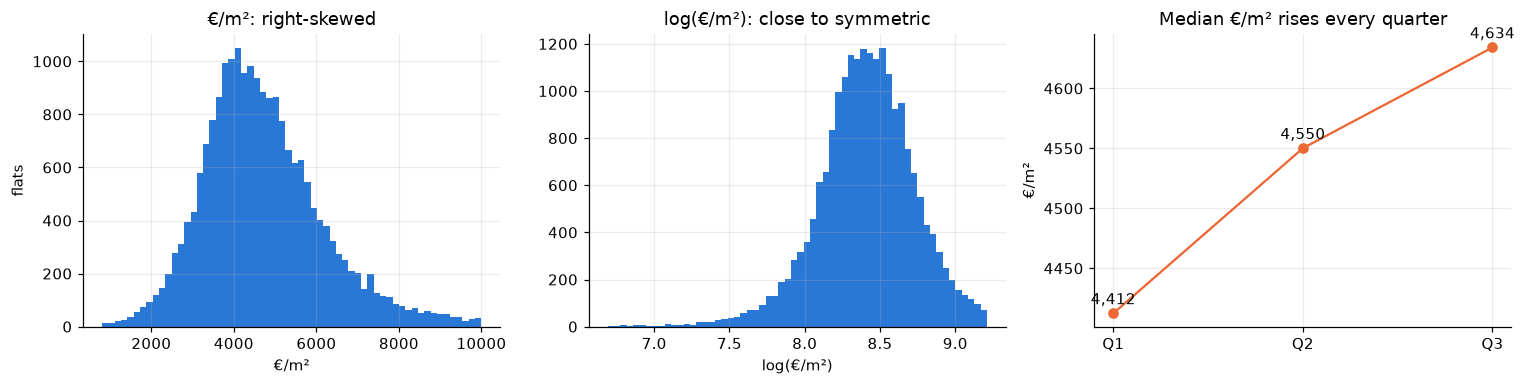

Average quarterly rise of the median: +2.5%  ->  a model that ignores time would undervalue Q4


In [5]:
is_train_final = df["PERIOD"] <= 201809          # Q1-Q3: final training set
is_test = df["PERIOD"] == 201812                 # Q4: test set, used once at the end
is_train_sel = df["PERIOD"] <= 201806            # Q1-Q2: training set while choosing the model
is_val = df["PERIOD"] == 201809                  # Q3: validation set while choosing the model

train_final, test = df[is_train_final], df[is_test]
train_sel, val = df[is_train_sel], df[is_val]

split_table = pd.DataFrame({
    "quarters": ["Q1-Q2", "Q3", "Q1-Q3", "Q4"],
    "role": ["train (model selection)", "validation", "train (final model)", "test"],
    "flats": [len(train_sel), len(val), len(train_final), len(test)],
}).set_index("quarters")
show(split_table)

eda = train_final  # every exploration plot uses training data only
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(np.exp(eda["LOG_UNITPRICE"]), bins=60, color=COLORS["sklearn"])
axes[0].set(title="€/m²: right-skewed", xlabel="€/m²", ylabel="flats")
axes[1].hist(eda["LOG_UNITPRICE"], bins=60, color=COLORS["sklearn"])
axes[1].set(title="log(€/m²): close to symmetric", xlabel="log(€/m²)")
drift = eda.groupby("QUARTER")["LOG_UNITPRICE"].agg(["median", "count"])
axes[2].plot(drift.index, np.exp(drift["median"]), marker="o", color=COLORS["manual"])
for q, v in np.exp(drift["median"]).items():
    axes[2].annotate(f"{v:,.0f}", (q, v), textcoords="offset points", xytext=(0, 6), ha="center")
axes[2].set(title="Median €/m² rises every quarter", ylabel="€/m²")
save_fig(fig, "target_and_drift")
q_growth = np.exp(drift["median"].diff().mean()) - 1
print(f"Average quarterly rise of the median: {q_growth:+.1%}  ->  a model that ignores time would undervalue Q4")

## 5. Feature engineering: evidence first

A linear regression can only draw straight lines. The four plots below (training data only) show four relationships that
are **not** straight lines with the raw columns. Each one motivates a group ("block") of engineered features.

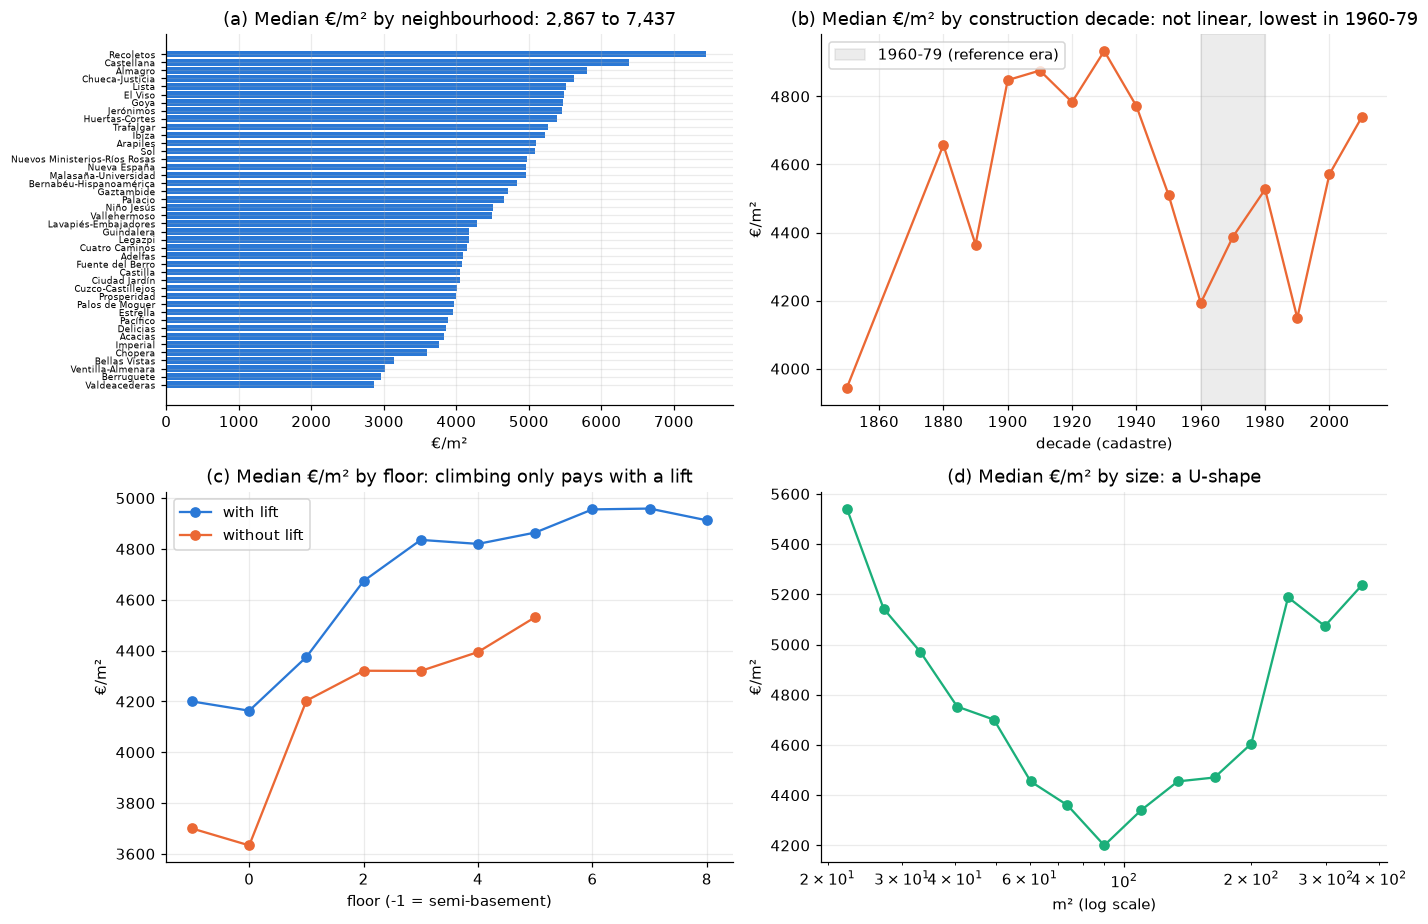

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# (a) location: within the central districts the median EUR/m2 of a neighbourhood ranges 2.6x
nb = eda.groupby(["DISTRICT", "NEIGHBOURHOOD"])["LOG_UNITPRICE"].median().pipe(np.exp).sort_values()
ax = axes[0, 0]
ax.barh(range(len(nb)), nb.values, color=COLORS["sklearn"], height=0.8)
ax.set_yticks(range(len(nb)), [n for _, n in nb.index], fontsize=6)
ax.set(title=f"(a) Median €/m² by neighbourhood: {nb.min():,.0f} to {nb.max():,.0f}", xlabel="€/m²")

# (b) age: not a straight line, lowest for 1960-79 buildings
decade = (eda["CADCONSTRUCTIONYEAR"] // 10 * 10).clip(lower=1850)
by_dec = eda.groupby(decade)["LOG_UNITPRICE"].agg(["median", "count"])
by_dec = by_dec[by_dec["count"] >= 50]
ax = axes[0, 1]
ax.plot(by_dec.index, np.exp(by_dec["median"]), marker="o", color=COLORS["manual"])
ax.axvspan(1960, 1980, color="grey", alpha=0.15, label="1960-79 (reference era)")
ax.set(title="(b) Median €/m² by construction decade: not linear, lowest in 1960-79",
       xlabel="decade (cadastre)", ylabel="€/m²")
ax.legend()

# (c) floor: going up only pays if there is a lift
fl = eda.assign(floor=eda["FLOORCLEAN"].clip(-1, 8), lift=eda["HASLIFT"].map({1: "with lift", 0: "without lift"}))
by_fl = fl.groupby(["lift", "floor"])["LOG_UNITPRICE"].agg(["median", "count"]).reset_index()
by_fl = by_fl[by_fl["count"] >= 30]
ax = axes[1, 0]
for name, color in [("with lift", COLORS["sklearn"]), ("without lift", COLORS["manual"])]:
    s = by_fl[by_fl["lift"] == name]
    ax.plot(s["floor"], np.exp(s["median"]), marker="o", color=color, label=name)
ax.set(title="(c) Median €/m² by floor: climbing only pays with a lift", xlabel="floor (-1 = semi-basement)", ylabel="€/m²")
ax.legend()

# (d) size: EUR/m2 falls with size, then rises again for the biggest flats (U-shape)
bins = np.exp(np.linspace(np.log(20), np.log(400), 16))
by_sz = eda.groupby(pd.cut(eda["CONSTRUCTEDAREA"], bins), observed=True)["LOG_UNITPRICE"].median().pipe(np.exp)
ax = axes[1, 1]
ax.plot([iv.mid for iv in by_sz.index], by_sz.values, marker="o", color=COLORS["module"])
ax.set_xscale("log")
ax.set(title="(d) Median €/m² by size: a U-shape", xlabel="m² (log scale)", ylabel="€/m²")
save_fig(fig, "feature_evidence")

**From evidence to features** (code: `pipeline.row_features`):

| Block | Features | Why |
|---|---|---|
| **trend** | `t_quarter` = 0, 1, 2, 3 | Prices rise each quarter (§4). A number lets the model extend the line into Q4. |
| **location** | one 0/1 column per neighbourhood (41, one is the reference); log distance to Castellana, to Sol and to the nearest metro | (a): location is the biggest driver. Distances in logs: the first few hundred metres matter most. Raw latitude/longitude would only allow a tilted plane over the map. |
| **building** | construction-era dummies (reference 1960–79), cadastral quality, new build, needs renovation, log of building height, log of flats in the building, doorman | (b): one dummy per era lets each era have its own premium; a single "year" coefficient could only go up or down. |
| **floor** | floor, `floors_without_lift` = floor × (no lift), ground floor, semi-basement, top floor, exterior, south-facing, "unknown" flags | (c): the value of height depends on the lift, which is an **interaction** between two columns. |
| **size & extras** | log m² and its square (measured from a 90 m² flat), m² per room, baths per room, studio, duplex, terrace, AC, storage room, wardrobes, pool, garden, parking included in the price, kitchen/furniture | (d): the square lets a straight-line model bend into a U. Parking included in the price raises €/m² without more flat. |

Everything that is **learned from data** (medians for missing values, the list of neighbourhoods, the mean and standard
deviation used to standardise each feature) is learned on the training rows only, inside `FeatureBuilder.fit_transform`,
and then applied unchanged to validation, test and the dashboard.

In [7]:
fb_demo = P.FeatureBuilder()
fb_demo.fit_transform(train_sel)
block_sizes = {b: len(P.BLOCK_COLUMNS[b]) for b in P.ENGINEERED_BLOCKS}
block_sizes["location"] += len(fb_demo.neighbourhoods_) - 1
print("Features per block:", block_sizes, "| total:", len(fb_demo.feature_names_))
show(fb_demo.unscaled_frame(train_sel).describe().T.loc[
    ["t_quarter", "log_dist_castellana", "cadastral_quality", "floor", "floors_without_lift", "log_m2", "log_m2_sq", "m2_per_room"],
    ["mean", "std", "min", "max"]])

Features per block: {'trend': 1, 'location': 44, 'building': 11, 'floor': 10, 'size_extras': 15} | total: 81


,mean,std,min,max
t_quarter,0.4253,0.4944,0.0000,1.0000
log_dist_castellana,-0.0866,0.7122,-2.9674,0.9577
cadastral_quality,4.3689,1.3021,1.0000,9.0000
floor,2.7194,2.1436,0.0000,11.0000
floors_without_lift,0.4459,1.0564,0.0000,11.0000
log_m2,4.4914,0.5987,3.0445,5.9915
log_m2_sq,0.3585,0.4286,0.0000,2.2250
m2_per_room,43.0936,19.5747,9.1667,380.0000


## 6. Model selection on the validation quarter (Q3)

Every option is trained on **Q1–Q2** and scored on **Q3**, a quarter it has not seen. That mimics the real use: valuing
next quarter's listings. We use scikit-learn here because it gives the exact answer instantly; the PyTorch versions are
only needed for the final model.

Two simple baselines set the bar:
- **global median:** every flat gets the median €/m² of the training data;
- **neighbourhood median ("comps"):** every flat gets the median €/m² of its neighbourhood, which is what an analyst would do
  by hand. The model is only worth having if it beats *this*.

In [8]:
y_sel, y_val = train_sel["LOG_UNITPRICE"].to_numpy(), val["LOG_UNITPRICE"].to_numpy()


def validate(alpha=0.0, **fb_kwargs):
    # train on Q1-Q2, score on Q3. alpha = 0 is plain linear regression; alpha > 0 is Ridge
    fb = P.FeatureBuilder(**fb_kwargs)
    X_tr = fb.fit_transform(train_sel)
    model = LinearRegression() if alpha == 0 else Ridge(alpha=alpha)
    model.fit(X_tr, y_sel)
    return P.regression_metrics(y_val, model.predict(fb.transform(val))), X_tr.shape[1]


rows = []
glob_med = np.median(y_sel)
rows.append({"candidate": "baseline: global median", "n_features": 0,
             **P.regression_metrics(y_val, np.full(len(val), glob_med))})
nb_med = pd.Series(y_sel).groupby(train_sel["NEIGHBOURHOOD"].to_numpy()).median()
rows.append({"candidate": "baseline: neighbourhood median", "n_features": 0,
             **P.regression_metrics(y_val, val["NEIGHBOURHOOD"].map(nb_med).fillna(glob_med))})
m, p = validate(blocks=("raw",))
rows.append({"candidate": "linear regression, raw columns", "n_features": p, **m})
m, p = validate()
rows.append({"candidate": "linear regression, engineered features", "n_features": p, **m})
selection = pd.DataFrame(rows).set_index("candidate")
show(selection[["n_features", "RMSE_log", "R2_log", "MdAPE_%", "PPE10_%", "PPE20_%", "median_bias_%"]])

,n_features,RMSE_log,R2_log,MdAPE_%,PPE10_%,PPE20_%,median_bias_%
candidate,,,,,,,
baseline: global median,0,0.3137,-0.0081,19.4510,25.7414,51.3790,-3.3259
baseline: neighbourhood median,0,0.2521,0.3493,14.9664,34.4751,63.4342,-3.8560
"linear regression, raw columns",34,0.2415,0.4027,14.4164,35.5724,64.4870,-0.9246
"linear regression, engineered features",81,0.2061,0.5648,11.4392,44.6767,74.6293,-0.2344


**Ablation: does every block earn its place?** Remove one block at a time and measure how much worse the validation error gets.
A block that does not hurt when removed should not be there.

,n_features,RMSE_log,MdAPE_%,ΔRMSE_log,ΔMdAPE_pp,median_bias_%
block removed,,,,,,
location,37,0.2581,15.9301,0.0519,4.4909,-1.4195
size_extras,66,0.2268,13.6045,0.0207,2.1653,-0.0774
floor,71,0.2226,12.6156,0.0165,1.1764,-0.6317
building,70,0.2105,11.7665,0.0044,0.3273,-0.1783
trend,80,0.2086,11.5347,0.0024,0.0956,-3.4297


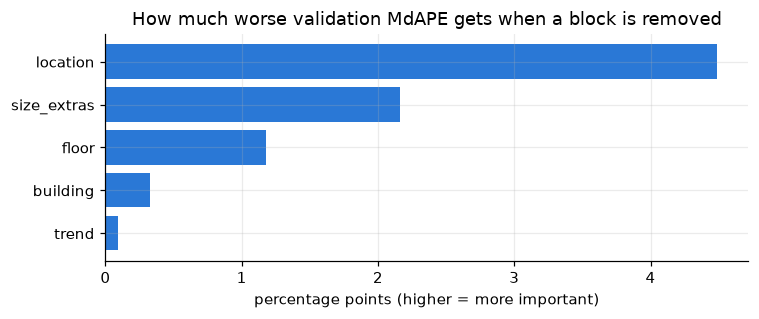

In [9]:
full = tuple(P.ENGINEERED_BLOCKS)
ref = selection.loc["linear regression, engineered features"]
abl = []
for block in full:
    m, p = validate(blocks=tuple(b for b in full if b != block))
    abl.append({"block removed": block, "n_features": p, "RMSE_log": m["RMSE_log"], "MdAPE_%": m["MdAPE_%"],
                "ΔRMSE_log": m["RMSE_log"] - ref["RMSE_log"], "ΔMdAPE_pp": m["MdAPE_%"] - ref["MdAPE_%"],
                "median_bias_%": m["median_bias_%"]})
ablation = pd.DataFrame(abl).set_index("block removed").sort_values("ΔRMSE_log", ascending=False)
show(ablation)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(ablation.index[::-1], ablation["ΔMdAPE_pp"][::-1], color=COLORS["sklearn"])
ax.set(title="How much worse validation MdAPE gets when a block is removed", xlabel="percentage points (higher = more important)")
save_fig(fig, "ablation")
assert (ablation["ΔRMSE_log"] > 0).all(), "every block should improve validation error"

Reading the ablation: **location** matters most, then **size & extras** and **floor**. Removing the **trend** barely moves
the error, but look at `median_bias_%`: without it the model undervalues Q3 by about 3%, the market rise. The error moves
little but becomes *systematically* wrong in one direction, which for an investor is the worse kind.

**Regularisation check.** Ridge regression adds a penalty that shrinks the weights, which helps when there are many
features and few rows. Here we have ~14,000 rows for ~80 features, so we expect it not to help. We check instead of assuming:

In [10]:
alphas = [0, 1, 10, 100, 1_000, 10_000]
alpha_scan = pd.DataFrame([{"alpha": a, **validate(alpha=a)[0]} for a in alphas]).set_index("alpha")
show(alpha_scan[["RMSE_log", "MdAPE_%", "PPE10_%"]])
gain = alpha_scan.loc[0, "RMSE_log"] - alpha_scan["RMSE_log"].min()
print(f"Best Ridge improves validation RMSE by only {gain:.5f} over plain linear regression.")
print("Decision: plain linear regression (no regularisation) for all three implementations.")

,RMSE_log,MdAPE_%,PPE10_%
alpha,,,
0,0.2061,11.4392,44.6767
1,0.2061,11.4400,44.7212
10,0.2061,11.4485,44.7212
100,0.2061,11.4806,44.7212
1000,0.2075,11.6911,44.3802
10000,0.2283,13.4771,37.8855


Best Ridge improves validation RMSE by only 0.00001 over plain linear regression.
Decision: plain linear regression (no regularisation) for all three implementations.


## 7. Final input matrices

The `FeatureBuilder` is now learned on **Q1–Q3** (the final training set) and applied to **Q4**. The same two matrices
feed all three implementations, so any difference between them can only come from *how* each one finds the weights.

In [11]:
fb = P.FeatureBuilder()
X_train = fb.fit_transform(train_final)     # learns medians, neighbourhoods, means/stds on Q1-Q3
X_test = fb.transform(test)                 # applies them to Q4
y_train = train_final["LOG_UNITPRICE"].to_numpy()
y_test = test["LOG_UNITPRICE"].to_numpy()
n_train, n_features = X_train.shape
print(f"X_train {X_train.shape}, X_test {X_test.shape}")
print(f"after standardising, training columns have mean ~0 (max {np.abs(X_train.mean(0)).max():.0e}) and std 1")

X_train (20777, 81), X_test (14973, 81)
after standardising, training columns have mean ~0 (max 7e-16) and std 1


## 8. Method 1: scikit-learn

`LinearRegression` finds the weights that minimise the mean squared error **exactly**, in one step, using linear algebra
(least squares). There is no learning rate and there are no epochs. That makes it the reference answer the two PyTorch
versions should reproduce.

In [12]:
t0 = time.perf_counter()
sk_model = LinearRegression().fit(X_train, y_train)
sk_time = time.perf_counter() - t0
sk_pred = sk_model.predict(X_test)
print(f"fitted in {sk_time * 1000:.0f} ms; intercept {sk_model.intercept_:.4f} = log({np.exp(sk_model.intercept_):,.0f} €/m²), "
      "the predicted €/m² of a flat with every feature at its training average")

fitted in 86 ms; intercept 8.4085 = log(4,485 €/m²), the predicted €/m² of a flat with every feature at its training average


## 9. Method 2: PyTorch by hand (raw tensors, autograd, manual update)

Same model, same loss (mean squared error), but the weights are found by **gradient descent**: start from zero, compute
the error, ask autograd for the gradient (which direction makes the error grow), take a small step the other way, repeat.

```
w, b = 0, 0
repeat for each epoch:
    prediction = X @ w + b
    loss       = mean((prediction - y)^2)
    loss.backward()             # autograd computes d loss / d w and d loss / d b
    w = w - lr * gradient_w     # the step we write ourselves
    b = b - lr * gradient_b
    reset the gradients to zero # otherwise PyTorch adds them up across epochs
```

Every epoch uses all training rows at once ("full batch"). The only knob is the **learning rate** (step size), chosen
with a short sweep on the selection split (train Q1–Q2, check Q3).

,diverged,train loss after 2000 epochs,validation RMSE,max |w - w_sklearn|
lr,,,,
0.0100,False,0.0459,0.2063,0.0209
0.0500,False,0.0457,0.2061,0.0013
0.1000,False,0.0457,0.2061,0.0000
0.2000,False,0.0457,0.2061,0.0000
0.3000,True,inf,NaN,NaN


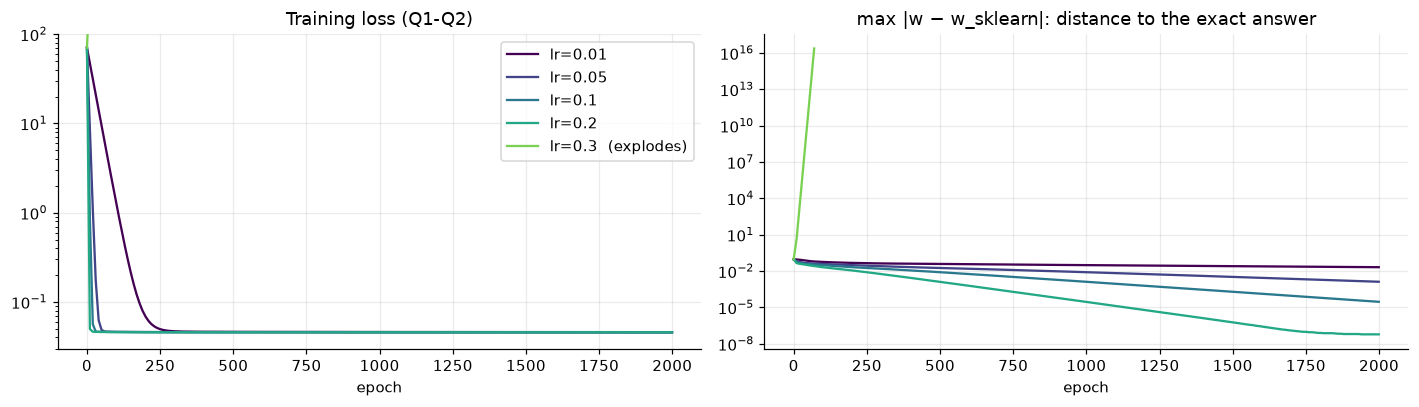

In [13]:
def to_t(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32)


def train_manual(X, y, lr, epochs, X_val=None, y_val=None, w_ref=None, track_every=10):
    w = torch.zeros(X.shape[1], requires_grad=True)   # one weight per feature, start at 0
    b = torch.zeros(1, requires_grad=True)            # intercept
    hist = {"epoch": [], "train_loss": [], "val_rmse": [], "dist_to_sklearn": []}
    for epoch in range(epochs):
        y_hat = X @ w + b                             # 1. forward pass: predictions
        loss = torch.mean((y_hat - y) ** 2)           # 2. mean squared error
        loss.backward()                               # 3. autograd fills w.grad and b.grad
        with torch.no_grad():                         # 4. the update itself must not be tracked
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()                                # 5. clear gradients (they accumulate otherwise)
        b.grad.zero_()

        if not np.isfinite(loss.item()):              # the learning rate was too big: stop
            hist["epoch"].append(epoch); hist["train_loss"].append(float("inf"))
            hist["val_rmse"].append(float("nan")); hist["dist_to_sklearn"].append(float("nan"))
            break
        if epoch % track_every == 0 or epoch == epochs - 1:   # bookkeeping for the plots
            hist["epoch"].append(epoch)
            hist["train_loss"].append(loss.item())
            with torch.no_grad():
                hist["val_rmse"].append(torch.sqrt(torch.mean((X_val @ w + b - y_val) ** 2)).item()
                                        if X_val is not None else float("nan"))
            # how far are we from the exact scikit-learn weights? (largest gap over all weights)
            hist["dist_to_sklearn"].append(float(np.abs(w.detach().numpy() - w_ref).max())
                                           if w_ref is not None else float("nan"))
    return w.detach(), b.detach(), hist


# selection split as tensors, and the exact scikit-learn answer on it (to measure the distance)
fb_sel = P.FeatureBuilder()
X_sel = fb_sel.fit_transform(train_sel)
X_val = fb_sel.transform(val)
Xt_sel, yt_sel, Xt_val, yt_val = to_t(X_sel), to_t(y_sel), to_t(X_val), to_t(y_val)
sk_sel = LinearRegression().fit(X_sel, y_sel)

sweep = {}
for lr in [0.01, 0.05, 0.1, 0.2, 0.3]:
    *_, h = train_manual(Xt_sel, yt_sel, lr, 2_000, Xt_val, yt_val, w_ref=sk_sel.coef_)
    sweep[lr] = h
lr_table = pd.DataFrame({lr: {"diverged": not np.isfinite(h["train_loss"][-1]),
                              "train loss after 2000 epochs": h["train_loss"][-1],
                              "validation RMSE": h["val_rmse"][-1],
                              "max |w - w_sklearn|": h["dist_to_sklearn"][-1]}
                         for lr, h in sweep.items()}).T
lr_table.index.name = "lr"
show(lr_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
cmap = plt.get_cmap("viridis")
for i, (lr, h) in enumerate(sweep.items()):
    diverged = not np.isfinite(h["train_loss"][-1])
    style = dict(color=cmap(i / len(sweep)), label=f"lr={lr}" + ("  (explodes)" if diverged else ""))
    axes[0].plot(h["epoch"], h["train_loss"], **style)
    axes[1].plot(h["epoch"], h["dist_to_sklearn"], **style)
axes[0].set(yscale="log", ylim=(0.03, 100), title="Training loss (Q1-Q2)", xlabel="epoch")
axes[1].set(yscale="log", title="max |w − w_sklearn|: distance to the exact answer", xlabel="epoch")
axes[0].legend()
save_fig(fig, "manual_lr_sweep")

**What the sweep shows.**
- **Too large (0.3): the loss explodes.** Each step overshoots the bottom of the error "bowl" and lands higher on the other
  side, further away every time.
- **Too small (0.01): it is safe but slow.** After 2,000 epochs it is still far from the exact answer.
- **0.1 and 0.2** reach the scikit-learn weights to many decimals.

**Choice: `lr = 0.1`**, half of the largest learning rate that still worked. 0.2 is faster, but it sits close to the value that
explodes; halving it leaves a safety margin when the training data changes (Q1–Q3 instead of Q1–Q2). The plot shows lr = 0.1
needs about 3,000 epochs to reach the exact answer, so the final model trains for **4,000**.

In [14]:
stable = [lr for lr, h in sweep.items() if np.isfinite(h["train_loss"][-1])]
LR_MANUAL = max(stable) / 2
EPOCHS_MANUAL = 4_000
print(f"largest stable lr = {max(stable)} -> chosen lr = {LR_MANUAL}, {EPOCHS_MANUAL:,} epochs")

Xt_train, yt_train, Xt_test = to_t(X_train), to_t(y_train), to_t(X_test)
t0 = time.perf_counter()
w_manual, b_manual, hist_manual = train_manual(Xt_train, yt_train, LR_MANUAL, EPOCHS_MANUAL,
                                               w_ref=sk_model.coef_, track_every=25)
manual_time = time.perf_counter() - t0
with torch.no_grad():
    manual_pred = (Xt_test @ w_manual + b_manual).numpy()
print(f"trained in {manual_time:.1f} s; final loss {hist_manual['train_loss'][-1]:.6f}; "
      f"largest weight gap vs scikit-learn = {np.abs(w_manual.numpy() - sk_model.coef_).max():.1e}")

largest stable lr = 0.2 -> chosen lr = 0.1, 4,000 epochs


trained in 3.1 s; final loss 0.044578; largest weight gap vs scikit-learn = 4.9e-07


## 10. Method 3: standard PyTorch workflow (`nn.Module` + `torch.optim` + `DataLoader`)

The model is `pipeline.LinearRegressionModel`: one `nn.Linear` layer, no activation, so it *is* a linear regression. Training uses the
standard loop:

```
for each epoch:
    for each mini-batch of 256 shuffled flats:     # DataLoader
        optimizer.zero_grad()                       # clear old gradients
        loss = MSELoss(model(x_batch), y_batch)     # forward pass + loss
        loss.backward()                             # gradients
        optimizer.step()                            # SGD update: w = w - lr * gradient
```

The difference from method 2: each step looks at **256 flats instead of all of them** (mini-batch stochastic gradient descent).
That is how this workflow is used when data is too big for one batch. Each step is cheaper but **noisier**: the gradient of 256
flats is only an estimate of the gradient of all of them. Again, the learning rate is the only knob, chosen on the selection split.

,validation RMSE (epoch 60),"ups and downs of val RMSE (std, last 10 epochs)","max |w - w_sklearn| (mean, last 10 epochs)"
lr,,,
0.0030,0.2063,0.0000,0.0307
0.0100,0.2062,0.0001,0.0091
0.0300,0.2073,0.0004,0.0045
0.1000,0.2132,0.0014,0.0114


scikit-learn on the same split: validation RMSE = 0.20613
Chosen lr for the standard workflow: 0.01


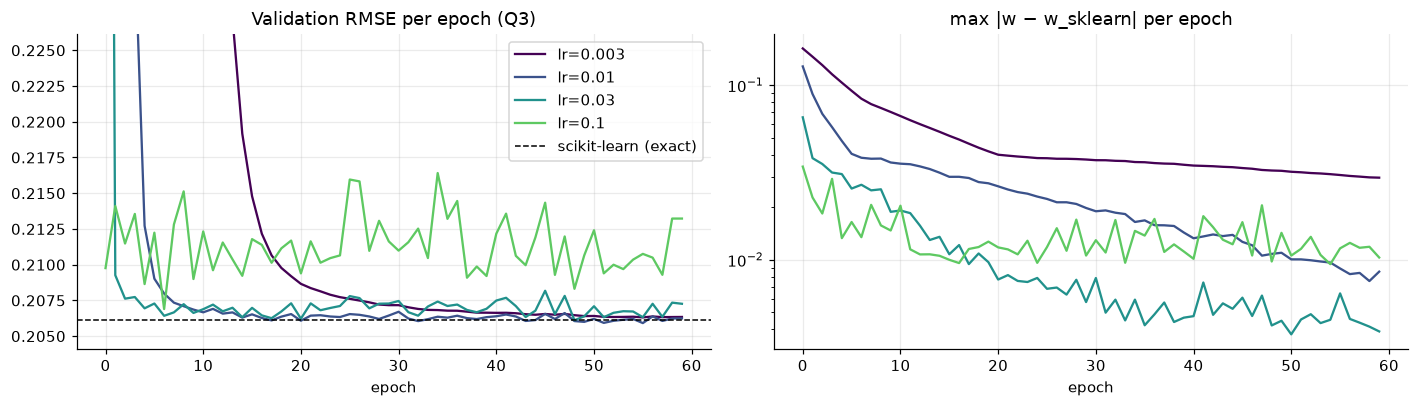

In [15]:
BATCH = 256


def train_module(X, y, lr, epochs, X_val=None, y_val=None, w_ref=None):
    torch.manual_seed(SEED)                                   # same initial weights every run
    model = P.LinearRegressionModel(X.shape[1])
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    criterion = torch.nn.MSELoss()                            # mean squared error, as in methods 1 and 2
    loader = DataLoader(TensorDataset(X, y), batch_size=BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    hist = {"epoch": [], "train_loss": [], "val_rmse": [], "dist_to_sklearn": []}
    for epoch in range(epochs):
        model.train()
        running, seen = 0.0, 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
            seen += len(xb)
        model.eval()
        with torch.no_grad():                                 # bookkeeping for the plots
            hist["epoch"].append(epoch)
            hist["train_loss"].append(running / seen)
            hist["val_rmse"].append(torch.sqrt(torch.mean((model(X_val) - y_val) ** 2)).item()
                                    if X_val is not None else float("nan"))
            hist["dist_to_sklearn"].append(float(np.abs(model.linear.weight.detach().numpy().ravel() - w_ref).max())
                                           if w_ref is not None else float("nan"))
    return model, hist


module_sweep = {}
for lr in [0.003, 0.01, 0.03, 0.1]:
    _, h = train_module(Xt_sel, yt_sel, lr, 60, Xt_val, yt_val, w_ref=sk_sel.coef_)
    module_sweep[lr] = h
sk_val_rmse = float(np.sqrt(np.mean((sk_sel.predict(X_val) - y_val) ** 2)))
mod_table = pd.DataFrame({lr: {"validation RMSE (epoch 60)": h["val_rmse"][-1],
                               "ups and downs of val RMSE (std, last 10 epochs)": float(np.std(h["val_rmse"][-10:])),
                               "max |w - w_sklearn| (mean, last 10 epochs)": float(np.mean(h["dist_to_sklearn"][-10:]))}
                          for lr, h in module_sweep.items()}).T
mod_table.index.name = "lr"
show(mod_table)
print(f"scikit-learn on the same split: validation RMSE = {sk_val_rmse:.5f}")
LR_MODULE = float(mod_table["validation RMSE (epoch 60)"].idxmin())
print("Chosen lr for the standard workflow:", LR_MODULE)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for i, (lr, h) in enumerate(module_sweep.items()):
    c = cmap(i / len(module_sweep))
    axes[0].plot(h["epoch"], h["val_rmse"], color=c, label=f"lr={lr}")
    axes[1].plot(h["epoch"], h["dist_to_sklearn"], color=c, label=f"lr={lr}")
axes[0].axhline(sk_val_rmse, color="black", ls="--", lw=1, label="scikit-learn (exact)")
axes[0].set(title="Validation RMSE per epoch (Q3)", xlabel="epoch", ylim=(sk_val_rmse - 0.002, sk_val_rmse + 0.02))
axes[1].set(yscale="log", title="max |w − w_sklearn| per epoch", xlabel="epoch")
axes[0].legend()
save_fig(fig, "module_lr_sweep")

**What the sweep shows: a trade-off.** With a small learning rate (0.003) the model is still slowly approaching the answer after
60 epochs. With a large one (0.1) it gets there fast but each noisy mini-batch step kicks it around, so the validation error keeps
jumping up and down. **0.01** gives the lowest validation error. The final model trains for 100 epochs on Q1–Q3.

In [16]:
EPOCHS_MODULE = 100
t0 = time.perf_counter()
module_model, hist_module = train_module(Xt_train, yt_train, LR_MODULE, EPOCHS_MODULE, w_ref=sk_model.coef_)
module_time = time.perf_counter() - t0
module_model.eval()
with torch.no_grad():
    module_pred = module_model(Xt_test).numpy()
print(f"trained in {module_time:.1f} s; largest weight gap vs scikit-learn = "
      f"{np.abs(module_model.linear.weight.detach().numpy().ravel() - sk_model.coef_).max():.1e}")

trained in 28.6 s; largest weight gap vs scikit-learn = 3.3e-03


## 11. Comparison on the test quarter (Q4)

All rows below are scored on the same ~15,000 Q4 listings, which no step above has looked at. The baselines are recomputed
on Q1–Q3, like the models.

In [17]:
glob_med_f = np.median(y_train)
nb_med_f = pd.Series(y_train).groupby(train_final["NEIGHBOURHOOD"].to_numpy()).median()
preds = {
    "baseline: global median": np.full(len(test), glob_med_f),
    "baseline: neighbourhood median": test["NEIGHBOURHOOD"].map(nb_med_f).fillna(glob_med_f).to_numpy(),
    "scikit-learn LinearRegression": sk_pred,
    "PyTorch manual loop": manual_pred,
    "PyTorch nn.Module + SGD": module_pred,
}
times = {"scikit-learn LinearRegression": sk_time, "PyTorch manual loop": manual_time, "PyTorch nn.Module + SGD": module_time}
results = pd.DataFrame({k: P.regression_metrics(y_test, v) for k, v in preds.items()}).T
results["train_time_s"] = pd.Series(times)
show(results[["RMSE_log", "R2_log", "MdAPE_%", "PPE10_%", "PPE20_%", "median_bias_%", "train_time_s"]])

# do the three implementations agree? compare weights and predicted prices with scikit-learn
w = {"scikit-learn LinearRegression": sk_model.coef_, "PyTorch manual loop": w_manual.numpy(),
     "PyTorch nn.Module + SGD": module_model.linear.weight.detach().numpy().ravel()}
b = {"scikit-learn LinearRegression": sk_model.intercept_, "PyTorch manual loop": b_manual.item(),
     "PyTorch nn.Module + SGD": module_model.linear.bias.item()}
agreement = pd.DataFrame({
    k: {"largest |Δ weight|": np.abs(w[k] - sk_model.coef_).max(),
        "|Δ intercept|": abs(b[k] - sk_model.intercept_),
        "median |Δ predicted price| %": 100 * np.median(np.abs(np.exp(preds[k] - sk_pred) - 1)),
        "largest |Δ predicted price| %": 100 * np.abs(np.exp(preds[k] - sk_pred) - 1).max(),
        "correlation with sklearn predictions": np.corrcoef(preds[k], sk_pred)[0, 1]}
    for k in ["PyTorch manual loop", "PyTorch nn.Module + SGD"]}).T
show(agreement)

,RMSE_log,R2_log,MdAPE_%,PPE10_%,PPE20_%,median_bias_%,train_time_s
baseline: global median,0.3083,-0.0078,18.7798,27.4361,52.4945,-3.3814,NaN
baseline: neighbourhood median,0.2484,0.3457,14.6919,35.2234,64.3492,-3.0591,NaN
scikit-learn LinearRegression,0.2027,0.5642,11.4373,44.7472,75.6361,0.9636,0.0856
PyTorch manual loop,0.2027,0.5642,11.4376,44.7472,75.6361,0.9633,3.0881
PyTorch nn.Module + SGD,0.2030,0.5631,11.3988,44.7472,75.5226,0.8856,28.5878


,largest |Δ weight|,|Δ intercept|,median |Δ predicted price| %,largest |Δ predicted price| %,correlation with sklearn predictions
PyTorch manual loop,0.0000,0.0000,0.0002,0.0004,1.0000
PyTorch nn.Module + SGD,0.0033,0.0012,0.5832,3.3040,0.9994


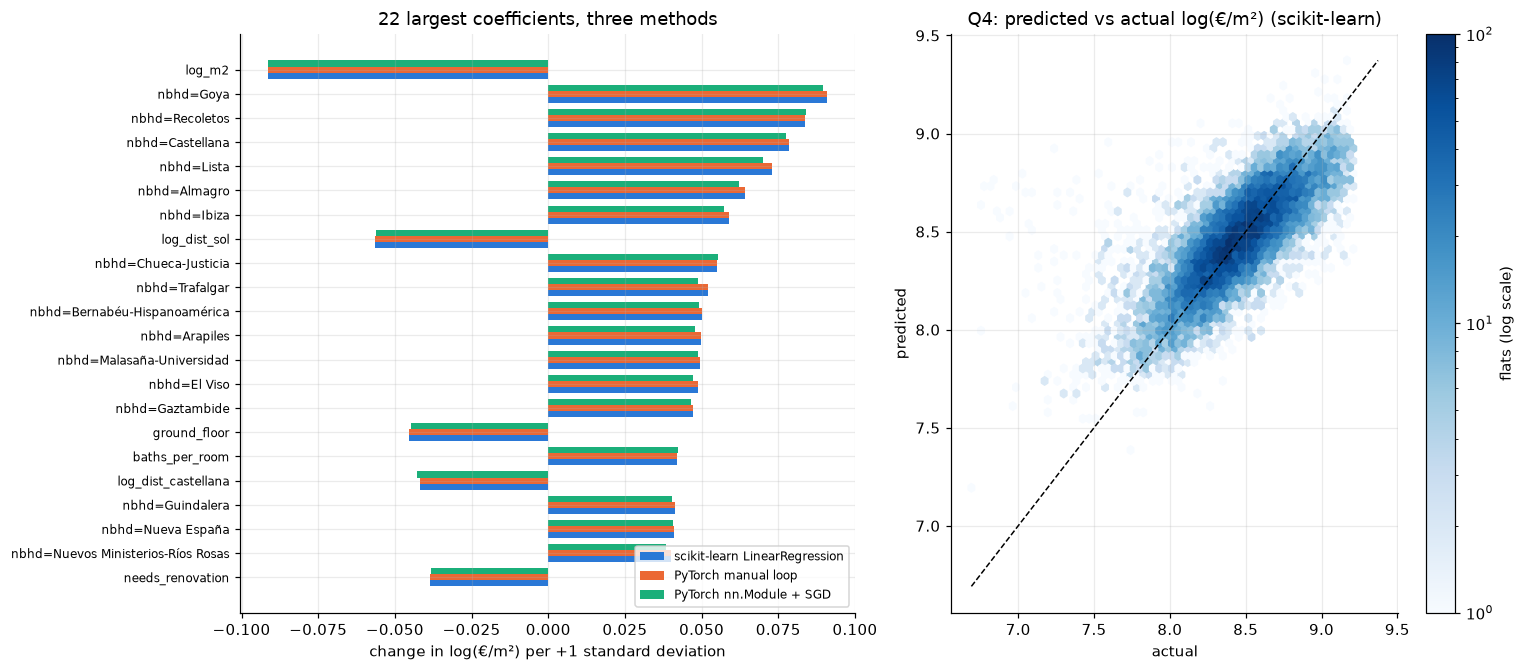

In [18]:
coef = pd.DataFrame({k: v for k, v in w.items()}, index=fb.feature_names_)
top = coef.reindex(coef["scikit-learn LinearRegression"].abs().sort_values(ascending=False).index).head(22)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.1, 1]})
yy = np.arange(len(top))
for off, (k, c) in zip([-0.25, 0, 0.25], [("scikit-learn LinearRegression", COLORS["sklearn"]),
                                          ("PyTorch manual loop", COLORS["manual"]),
                                          ("PyTorch nn.Module + SGD", COLORS["module"])]):
    axes[0].barh(yy + off, top[k], height=0.25, color=c, label=k)
axes[0].set_yticks(yy, top.index, fontsize=8)
axes[0].set(title="22 largest coefficients, three methods", xlabel="change in log(€/m²) per +1 standard deviation")
axes[0].legend(loc="lower right", fontsize=8)

hb = axes[1].hexbin(y_test, sk_pred, gridsize=60, bins="log", cmap="Blues", mincnt=1)
lims = [min(y_test.min(), sk_pred.min()), max(y_test.max(), sk_pred.max())]
axes[1].plot(lims, lims, color="black", lw=1, ls="--")
axes[1].set(title="Q4: predicted vs actual log(€/m²) (scikit-learn)", xlabel="actual", ylabel="predicted")
fig.colorbar(hb, ax=axes[1], label="flats (log scale)")
save_fig(fig, "comparison")

### Do the three agree? Yes. And where they differ slightly, we know why.

All three minimise the **same error on the same data**, so they should find the same weights. Any gap comes from *how* each
one searches:

- **scikit-learn** solves the problem exactly in one step.
- **Manual loop (full-batch gradient descent)** walks downhill using all the data at every step. It gets closer every epoch
  and after 4,000 epochs matches scikit-learn up to float32 rounding (left plot below).
- **`nn.Module` + mini-batch SGD** walks downhill using 256 flats at a time. Each step points *roughly* the right way, so it gets
  close to the answer but keeps wobbling around it. With a fixed learning rate it never settles exactly (right plot). Its weights
  end ~0.003 away from scikit-learn's. In euros the predictions differ by about 0.6% for the typical flat (about 3% at most),
  small next to the ~11% valuation error, and every business metric agrees within 0.1 percentage points.
- The manual loop and `nn.Module` would match *exactly* if `nn.Module` also used the full batch with the same learning rate and starting
  weights: the maths is identical, only the batching differs.

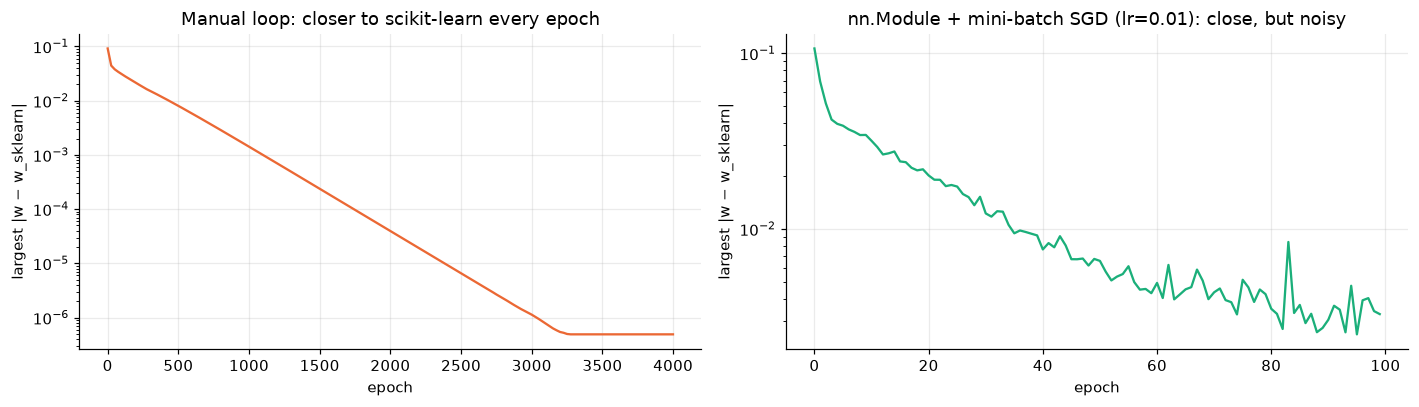

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(hist_manual["epoch"], hist_manual["dist_to_sklearn"], color=COLORS["manual"])
axes[0].set(yscale="log", title="Manual loop: closer to scikit-learn every epoch", xlabel="epoch",
            ylabel="largest |w − w_sklearn|")
axes[1].plot(hist_module["epoch"], hist_module["dist_to_sklearn"], color=COLORS["module"])
axes[1].set(yscale="log", title=f"nn.Module + mini-batch SGD (lr={LR_MODULE}): close, but noisy", xlabel="epoch",
            ylabel="largest |w − w_sklearn|")
save_fig(fig, "convergence")

**A shared bias, not a difference between methods.** All three overvalue Q4 by about 1% at the median. The trend coefficient
explains it:

In [20]:
t_idx = fb.feature_names_.index("t_quarter")
learned_trend = np.exp(sk_model.coef_[t_idx] / fb.std_[t_idx]) - 1    # undo the standardisation: per quarter
actual_q3_q4 = np.exp(np.median(y_test) - np.median(val["LOG_UNITPRICE"])) - 1
print(f"Trend learned from Q1-Q3: {learned_trend:+.1%} per quarter; actual rise of the median from Q3 to Q4: {actual_q3_q4:+.1%}")

Trend learned from Q1-Q3: +2.1% per quarter; actual rise of the median from Q3 to Q4: +1.1%


The model learned the first-half pace of the market and assumed it would continue; Q4 rose more slowly, so the forecast
overshoots by about a point. With more data the trend could be re-estimated every quarter or replaced by an official price index
(see Limitations in `REPORT.md`).

### What the coefficients say (in plain words)

Because of the log target, `exp(coefficient) − 1` is a **% premium** for a one-standard-deviation increase in the feature.
Neighbourhood dummies are left out here (each one is relative to the reference neighbourhood).

In [21]:
readable = coef.drop(index=[c for c in coef.index if c.startswith("nbhd=")])["scikit-learn LinearRegression"]
show((100 * (np.exp(readable) - 1)).sort_values().to_frame("% premium per +1 std").round(2))

,% premium per +1 std
log_m2,-8.7200
log_dist_sol,-5.5000
ground_floor,-4.4300
log_dist_castellana,-4.0800
needs_renovation,-3.8000
semi_basement,-3.5400
m2_per_room,-3.2300
floors_without_lift,-2.8900
cadastral_quality,-2.1500
studio,-1.1900


## 12. Business layer: the bargain screen

For each listing: **`discount = 1 − asking price / fair value`**. A positive discount means the flat asks less than comparable
flats.

**Choosing the threshold *d* without looking at the test set.** We use the validation quarter (model trained on Q1–Q2): the
discounts there show how big the "gaps" are on new listings. *d* = the **90th percentile**: only one listing in ten asks that far
below the model. We also check that *d* is clearly larger than the model's typical error (MdAPE), so a flag is not just model noise.
The dashboard lets the user raise *d* to match the team's capacity and see the number of visits and their cost.

**An upper cap.** At the extreme, discounts stop making sense. Some listings ask 80% less than similar flats, e.g. €900/m² in
Recoletos where the median is above €7,000/m². Those are not bargains but a different product the data cannot identify: bare
ownership (*nuda propiedad*), auctions, occupied flats, a share of a flat, or a typo. Sending an analyst there wastes a visit, so
discounts above the **99th percentile** of validation are set aside as *implausible: check the listing type*.

In [22]:
val_disc = P.discount_vs_fair_value(y_val, sk_sel.predict(X_val))
THRESHOLD = round(float(np.quantile(val_disc, 0.90)), 2)   # rounded to a whole percent: easier to communicate
CAP = round(float(np.quantile(val_disc, 0.99)), 2)
val_mdape = P.regression_metrics(y_val, sk_sel.predict(X_val))["MdAPE_%"]
print(f"threshold d = {THRESHOLD:.0%}  (validation MdAPE = {val_mdape:.1f}% -> d is {100 * THRESHOLD / val_mdape:.1f}x the typical error)")
print(f"implausibility cap = {CAP:.0%}")

COST_PER_VISIT_EUR = 400  # analyst half-day + preliminary appraisal: an assumption, adjustable in the dashboard
test_disc = P.discount_vs_fair_value(y_test, sk_pred)
fair_price = np.exp(sk_pred) * test["CONSTRUCTEDAREA"].to_numpy()
flag = (test_disc >= THRESHOLD) & (test_disc < CAP)
implausible = test_disc >= CAP
print(f"Q4: {flag.sum():,} of {len(test):,} listings flagged ({flag.mean():.1%}), {implausible.sum():,} set aside as implausible; "
      f"visit cost {flag.sum() * COST_PER_VISIT_EUR:,.0f} €")

show(test.assign(asking_eur_m2=np.exp(y_test), neighbourhood_median_eur_m2=np.exp(test["NEIGHBOURHOOD"].map(nb_med_f)),
                 discount=test_disc)
     .loc[implausible, ["NEIGHBOURHOOD", "CONSTRUCTEDAREA", "PRICE", "asking_eur_m2", "neighbourhood_median_eur_m2", "discount"]]
     .sort_values("discount", ascending=False).head(5).round(2))

threshold d = 20%  (validation MdAPE = 11.4% -> d is 1.7x the typical error)
implausibility cap = 45%
Q4: 1,459 of 14,973 listings flagged (9.7%), 167 set aside as implausible; visit cost 583,600 €


,NEIGHBOURHOOD,CONSTRUCTEDAREA,PRICE,asking_eur_m2,neighbourhood_median_eur_m2,discount
26886,Huertas-Cortes,89,"79,000.0000",887.6400,"5,382.3500",0.8600
24629,Recoletos,180,"162,000.0000",900.0000,"7,437.5000",0.8500
32524,Huertas-Cortes,86,"80,000.0000",930.2300,"5,382.3500",0.8500
27000,Cuatro Caminos,70,"59,000.0000",842.8600,"4,147.0100",0.8500
26247,Chueca-Justicia,40,"45,000.0000","1,125.0000","5,622.2200",0.8300


**Who gets flagged?** A sanity check: compare the flagged flats with all Q4 flats.

,flagged,all Q4
needs renovation,21.1000,22.7000
interior,23.4000,22.6000
ground floor or below,16.0000,11.4000


,% of listings flagged
DISTRICT,
Arganzuela,6.0000
Retiro,8.3000
Salamanca,8.4000
Chamartín,8.4000
Tetuán,9.7000
Chamberí,10.2000
Centro,13.2000


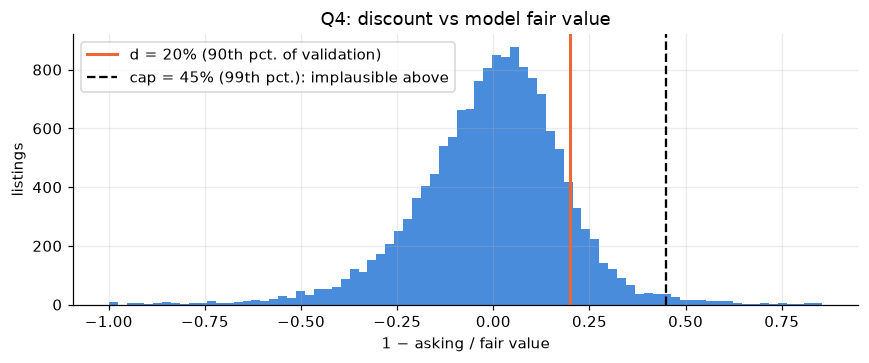

In [23]:
def traits(d):
    return pd.Series({"needs renovation": d["BUILTTYPEID_2"].mean(),
                      "interior": (d["FLATLOCATIONID"] == 2).mean(),
                      "ground floor or below": (d["FLOORCLEAN"] <= 0).mean()})


profile = pd.DataFrame({"flagged": traits(test[flag]), "all Q4": traits(test)})
show((100 * profile).round(1))
by_district = pd.Series(flag, index=test.index).groupby(test["DISTRICT"]).mean().mul(100).round(1).sort_values()
show(by_district.to_frame("% of listings flagged"))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(np.clip(test_disc, -1, 1), bins=80, color=COLORS["sklearn"], alpha=0.85)
ax.axvline(THRESHOLD, color=COLORS["manual"], lw=2, label=f"d = {THRESHOLD:.0%} (90th pct. of validation)")
ax.axvline(CAP, color="black", lw=1.5, ls="--", label=f"cap = {CAP:.0%} (99th pct.): implausible above")
ax.set(title="Q4: discount vs model fair value", xlabel="1 − asking / fair value", ylabel="listings")
ax.legend()
save_fig(fig, "bargain_threshold")

**Reading this honestly.** The model only knows what is in the ad. A flagged flat is cheap *compared with what the ad says*. It may
be a real bargain, or it may have a problem the data does not record (state beyond the three condition categories, light, street
noise, a tenant). The profile table helps: flats needing renovation and interior flats are flagged at about their normal rate, so
the model already accounts for them. Ground-floor flats and Centro are flagged more often than average, which points to things the
model cannot see (street noise and privacy at street level; very uneven buildings in the old centre). That is why the output is a
**list of flats to visit**, not a list of flats to buy.

## 13. Saving the artifacts for the dashboard

The dashboard (`app.py`) loads these files and **never trains anything**:

| File | Content |
|---|---|
| `sklearn_linear_regression.joblib` | fitted scikit-learn model |
| `torch_manual.pt` | the `w` and `b` tensors from the manual loop |
| `torch_module.pt` | the `state_dict` (weights) of `LinearRegressionModel` |
| `feature_builder.joblib` | the fitted `FeatureBuilder` (medians, neighbourhood list, means/stds) |
| `listings_model.csv.gz` | the cleaned Q1–Q4 listings with their split label |
| `metrics.json` | settings, test metrics, agreement and validation tables |
| `training_history.json` | the training curves of both PyTorch models |

In [24]:
joblib.dump(sk_model, ART / "sklearn_linear_regression.joblib")
torch.save({"w": w_manual, "b": b_manual}, ART / "torch_manual.pt")
torch.save(module_model.state_dict(), ART / "torch_module.pt")
joblib.dump(fb, ART / "feature_builder.joblib")

keep = list(dict.fromkeys(["ASSETID", "PERIOD", "QUARTER", "PRICE", "CONSTRUCTEDAREA", "LOG_UNITPRICE", "NEIGHBOURHOOD",
                           "DISTRICT"] + P.RAW_COLUMNS + ["ISPARKINGSPACEINCLUDEDINPRICE"]))
df.assign(SPLIT=np.where(is_test, "test", "train"))[keep + ["SPLIT"]].to_csv(
    ART / "listings_model.csv.gz", index=False, compression="gzip")

config = {"universe": "central almond (districts 01-07), <= 400 m2", "target": "log(EUR/m2)",
          "split": {"selection": "Q1-Q2 -> Q3", "final": "Q1-Q3 -> Q4"},
          "model": "plain linear regression (Ridge checked, no gain)", "lr_manual": LR_MANUAL,
          "epochs_manual": EPOCHS_MANUAL, "lr_module": LR_MODULE, "epochs_module": EPOCHS_MODULE, "batch_size": BATCH,
          "bargain_threshold": THRESHOLD, "bargain_cap": CAP, "cost_per_visit_eur": COST_PER_VISIT_EUR,
          "validation_mdape": val_mdape, "n_train": int(n_train), "n_test": int(len(test)), "n_features": int(n_features)}
metrics = {"config": config,
           "test_metrics": results.reset_index(names="method").to_dict(orient="records"),
           "agreement": agreement.reset_index(names="method").to_dict(orient="records"),
           "validation_selection": selection.reset_index().to_dict(orient="records"),
           "validation_ablation": ablation.reset_index().to_dict(orient="records"),
           "validation_alpha": alpha_scan.reset_index().to_dict(orient="records"),
           "cleaning_log": clean_log.to_dict(orient="records")}
(ART / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
(ART / "training_history.json").write_text(json.dumps({"manual": hist_manual, "module": hist_module}, default=float))
print("Saved:", sorted(p.name for p in ART.iterdir() if p.is_file()))

Saved: ['feature_builder.joblib', 'listings_model.csv.gz', 'metrics.json', 'sklearn_linear_regression.joblib', 'torch_manual.pt', 'torch_module.pt', 'training_history.json']


## Summary

- **Feature engineering pays.** On unseen data the engineered model values the typical flat within ~11%, against ~15% for the
  neighbourhood-median rule of thumb and ~14% for the same regression on the raw columns. Every block earns its place in the
  ablation; dropping the trend makes the model systematically undervalue by the market's rise.
- **The three implementations agree.** The manual loop reaches the scikit-learn answer to float32 precision; mini-batch SGD ends
  very close and wobbles a little because of its noisy steps. The business metrics are the same.
- **The bargain screen** turns the model into a decision, with a threshold set from validation errors and a cap for implausible
  listings. Explore it in the dashboard: `uv run python main.py app`.